# Production Multi-Head Training Pipeline for Oral Cavity Screening

This notebook implements a production-grade multi-head EfficientNetB1 model for oral cavity cancer screening.

## Architecture Overview

**Backbone:** EfficientNetB1 (pretrained on ImageNet)

**Heads:**
- **Head A:** 5-class fine-grained classification (Healthy, Benign, OPMD, OCA, Unknown)
- **Head B:** Binary risk score (High-risk: OPMD+OCA vs Low-risk: Healthy+Benign)
- **Head C:** Oral vs Non-oral filter (Unknown detection)

**Export:** TFLite with dynamic range and INT8 quantization options

## Datasets Used

This notebook uses **TWO datasets** for multi-task learning:

1. **Dataset A (5-class):** `~/dev/oral_cavity_5class_dataset`
   - train/val/test splits with Benign, Healthy, OCA, OPMD, Unknown
   - Provides supervision for all 3 heads
   - Used for training, validation, AND evaluation

2. **Dataset B (Binary):** `~/dev/oral_cavity_binary_dataset`
   - cancer / non-cancer folders (NO train/val/test split)
   - **Used for TRAINING ONLY** - augments Head B (risk) supervision
   - Improves sensitivity for screening use case
   - NOT used for validation/evaluation (5-class test set covers this)

**Training Strategy:** Alternating batches from both datasets (as per MULTI_HEAD_MODEL_APPROACH.md)

**Evaluation Strategy:** All evaluation metrics computed on 5-class test set only

## Expected Performance
- F1 Score (weighted): 0.78-0.84
- Sensitivity for high-risk: >= 0.90
- Model size: ~10MB (TFLite quantized)

In [69]:
# Cell 1: Setup and Configuration
import os
import json
import random
import warnings
from pathlib import Path
from datetime import datetime
from typing import Tuple, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from tqdm import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, optimizers, callbacks
from tensorflow.keras.applications import EfficientNetB1

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

import albumentations as A

warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")
print(f"Metal plugin: {tf.config.list_physical_devices('GPU')}")

# Configuration
CONFIG = {
    # Data settings - TWO DATASETS
    'data_dir_5class': os.path.expanduser('~/dev/oral_cavity_5class_dataset'),  # 5-class dataset
    'data_dir_binary': os.path.expanduser('~/dev/oral_cavity_binary_dataset'),  # Binary dataset
    'ensemble_test_dir': os.path.expanduser('~/dev/oral_cavity_5class_dataset/test'),  # Test set for comparison (same structure as ensemble baseline)
    'image_size': (224, 224),
    'batch_size': 32,
    
    # Model settings
    'num_classes': 5,
    'class_names': ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown'],
    'binary_class_names': ['non-cancer', 'cancer'],  # Binary dataset classes
    'backbone': 'EfficientNetB1',
    'fine_tune_layers': 30,
    'dropout_rate': 0.3,
    
    # Training settings
    'epochs': 100,              # More epochs for multi-head convergence
    'learning_rate': 5e-5,      # Very conservative LR to prevent collapse
    'weight_decay': 1e-4,
    'label_smoothing': 0.05,     # Reduced from 0.1 to prevent over-regularization
    
    # Loss weights (prioritize risk detection for screening)
    'alpha': 1.0,   # 5-class weight
    'beta': 1.5,    # Risk weight (higher for screening sensitivity)
    'gamma': 0.5,   # Oral filter weight
    
    # Output settings
    'output_dir': './results/multihead_efficientnet',
    'experiment_name': f"multihead_{datetime.now().strftime('%Y%m%d_%H%M%S')}",
}

# Create output directories
output_path = Path(CONFIG['output_dir']) / CONFIG['experiment_name']
output_path.mkdir(parents=True, exist_ok=True)
(output_path / 'models').mkdir(exist_ok=True)
(output_path / 'plots').mkdir(exist_ok=True)
(output_path / 'tflite').mkdir(exist_ok=True)

# Save config
with open(output_path / 'config.json', 'w') as f:
    json.dump(CONFIG, f, indent=2)

print(f"\nExperiment: {CONFIG['experiment_name']}")
print(f"Output directory: {output_path}")
CONFIG

TensorFlow version: 2.15.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Metal plugin: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Experiment: multihead_20260128_221211
Output directory: results/multihead_efficientnet/multihead_20260128_221211


{'data_dir_5class': '/Users/alokdwivedi/dev/oral_cavity_5class_dataset',
 'data_dir_binary': '/Users/alokdwivedi/dev/oral_cavity_binary_dataset',
 'ensemble_test_dir': '/Users/alokdwivedi/dev/oral_cavity_5class_dataset/test',
 'image_size': (224, 224),
 'batch_size': 32,
 'num_classes': 5,
 'class_names': ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown'],
 'binary_class_names': ['non-cancer', 'cancer'],
 'backbone': 'EfficientNetB1',
 'fine_tune_layers': 30,
 'dropout_rate': 0.3,
 'epochs': 100,
 'learning_rate': 5e-05,
 'weight_decay': 0.0001,
 'label_smoothing': 0.05,
 'alpha': 1.0,
 'beta': 1.5,
 'gamma': 0.5,
 'output_dir': './results/multihead_efficientnet',
 'experiment_name': 'multihead_20260128_221211'}

In [70]:
# Cell 2: Data Loading and Path Setup (BOTH DATASETS)

def get_split_dirs(data_dir: str) -> Tuple[Path, Path, Path]:
    """Get train/val/test directory paths"""
    base = Path(data_dir)
    return base / 'train', base / 'val', base / 'test'


def load_image_paths_and_labels(data_dir: str, split: str, class_names: List[str]) -> Tuple[List[str], List[int]]:
    """Load all image paths and their labels for a given split"""
    base_path = Path(data_dir) / split
    image_paths = []
    labels = []
    
    for class_idx, class_name in enumerate(class_names):
        class_path = base_path / class_name
        if class_path.exists():
            for ext in ['*.jpg', '*.jpeg', '*.png']:
                for img_path in class_path.glob(ext):
                    image_paths.append(str(img_path))
                    labels.append(class_idx)
    
    return image_paths, labels


def load_binary_dataset(data_dir: str) -> Tuple[List[str], List[int]]:
    """
    Load binary dataset (cancer / non-cancer)
    
    Returns:
        image_paths: List of image paths
        labels: List of binary labels (0=non-cancer, 1=cancer)
    """
    base_path = Path(data_dir)
    image_paths = []
    labels = []
    
    # Binary classes: non-cancer=0, cancer=1
    binary_classes = [('non-cancer', 0), ('cancer', 1)]
    
    for class_name, label in binary_classes:
        class_path = base_path / class_name
        if class_path.exists():
            for ext in ['*.jpg', '*.jpeg', '*.png']:
                for img_path in class_path.glob(ext):
                    image_paths.append(str(img_path))
                    labels.append(label)
            print(f"  Binary {class_name}: {len([l for l in labels if l == label])} images")
        else:
            print(f"  Warning: {class_path} not found")
    
    return image_paths, labels


def create_derived_labels(y_class: np.ndarray, class_names: List[str]) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Create derived labels for multi-head training from 5-class labels
    
    Returns:
        y_risk: Binary risk labels (1=High-risk: OPMD+OCA, 0=Low-risk: Healthy+Benign)
        y_oral: Binary oral labels (1=Oral, 0=Non-oral/Unknown)
        mask_risk: Mask for valid risk labels (Unknown has no valid risk label)
    """
    # Class indices (alphabetically sorted by TensorFlow)
    # Benign=0, Healthy=1, OCA=2, OPMD=3, Unknown=4
    BENIGN, HEALTHY, OCA, OPMD, UNKNOWN = 0, 1, 2, 3, 4
    
    y_class = np.array(y_class)
    
    # Risk labels: High-risk (1) = OCA or OPMD, Low-risk (0) = Healthy or Benign
    y_risk = np.where((y_class == OCA) | (y_class == OPMD), 1.0, 0.0)
    
    # Oral labels: Oral (1) = all except Unknown, Non-oral (0) = Unknown
    y_oral = np.where(y_class != UNKNOWN, 1.0, 0.0)
    
    # Mask for valid risk labels (Unknown has no valid risk)
    mask_risk = np.where(y_class != UNKNOWN, 1.0, 0.0)
    
    return y_risk, y_oral, mask_risk


# =============================================
# DATASET A: 5-class dataset
# =============================================
print("=" * 60)
print("DATASET A: 5-CLASS DATASET")
print("=" * 60)

train_dir, val_dir, test_dir = get_split_dirs(CONFIG['data_dir_5class'])

print(f"Data directory: {CONFIG['data_dir_5class']}")
print(f"Train: {train_dir.exists()}")
print(f"Val: {val_dir.exists()}")
print(f"Test: {test_dir.exists()}")

# Load 5-class image paths and labels
train_paths_5class, train_labels_5class = load_image_paths_and_labels(CONFIG['data_dir_5class'], 'train', CONFIG['class_names'])
val_paths_5class, val_labels_5class = load_image_paths_and_labels(CONFIG['data_dir_5class'], 'val', CONFIG['class_names'])
test_paths_5class, test_labels_5class = load_image_paths_and_labels(CONFIG['data_dir_5class'], 'test', CONFIG['class_names'])

print(f"\n5-class dataset sizes:")
print(f"  Train: {len(train_paths_5class)} images")
print(f"  Val: {len(val_paths_5class)} images")
print(f"  Test: {len(test_paths_5class)} images")

# Create derived labels for 5-class dataset
train_risk_5class, train_oral_5class, train_mask_5class = create_derived_labels(train_labels_5class, CONFIG['class_names'])
val_risk_5class, val_oral_5class, val_mask_5class = create_derived_labels(val_labels_5class, CONFIG['class_names'])
test_risk_5class, test_oral_5class, test_mask_5class = create_derived_labels(test_labels_5class, CONFIG['class_names'])

print(f"\nDerived labels (from 5-class):")
print(f"  High-risk samples: Train={train_risk_5class.sum():.0f}, Val={val_risk_5class.sum():.0f}, Test={test_risk_5class.sum():.0f}")

# =============================================
# DATASET B: Binary dataset (for Head B supervision)
# =============================================
# 
# NOTE: Binary dataset is used for TRAINING ONLY (no val/test split needed)
# 
# Reasoning:
# 1. The binary dataset's purpose is to AUGMENT training for Head B (risk detection)
#    by providing additional cancer/non-cancer supervision
# 2. Evaluation is performed on the 5-class test set, where we derive risk labels
#    (OPMD + OCA = high-risk, Healthy + Benign = low-risk)
# 3. This approach is simpler and the 5-class test set already provides
#    comprehensive evaluation for all 3 heads
# 4. The binary dataset doesn't have 5-class labels, so it can't be used
#    for evaluating Head A (5-class) or Head C (oral filter)
#
print("\n" + "=" * 60)
print("DATASET B: BINARY DATASET (cancer / non-cancer)")
print("=" * 60)
print("NOTE: Binary dataset used for TRAINING ONLY (augments Head B supervision)")

print(f"Data directory: {CONFIG['data_dir_binary']}")

# Load binary dataset
train_paths_binary, train_labels_binary = load_binary_dataset(CONFIG['data_dir_binary'])

print(f"\nBinary dataset size: {len(train_paths_binary)} images")
print(f"  Cancer (high-risk): {sum(train_labels_binary)} images")
print(f"  Non-cancer (low-risk): {len(train_labels_binary) - sum(train_labels_binary)} images")

# Convert to numpy arrays
train_labels_binary = np.array(train_labels_binary, dtype=np.float32)

# =============================================
# SUMMARY
# =============================================
print("\n" + "=" * 60)
print("TRAINING DATA SUMMARY")
print("=" * 60)
print(f"Dataset A (5-class): {len(train_paths_5class)} training images")
print(f"  -> Provides supervision for: Head A (5-class), Head B (risk), Head C (oral)")
print(f"Dataset B (binary):  {len(train_paths_binary)} training images")
print(f"  -> Provides supervision for: Head B (risk) ONLY")
print(f"\nTotal unique training samples: {len(train_paths_5class) + len(train_paths_binary)}")

DATASET A: 5-CLASS DATASET
Data directory: /Users/alokdwivedi/dev/oral_cavity_5class_dataset
Train: True
Val: True
Test: True

5-class dataset sizes:
  Train: 2757 images
  Val: 531 images
  Test: 534 images

Derived labels (from 5-class):
  High-risk samples: Train=1191, Val=244, Test=245

DATASET B: BINARY DATASET (cancer / non-cancer)
NOTE: Binary dataset used for TRAINING ONLY (augments Head B supervision)
Data directory: /Users/alokdwivedi/dev/oral_cavity_binary_dataset
  Binary non-cancer: 750 images
  Binary cancer: 884 images

Binary dataset size: 1634 images
  Cancer (high-risk): 884 images
  Non-cancer (low-risk): 750 images

TRAINING DATA SUMMARY
Dataset A (5-class): 2757 training images
  -> Provides supervision for: Head A (5-class), Head B (risk), Head C (oral)
Dataset B (binary):  1634 training images
  -> Provides supervision for: Head B (risk) ONLY

Total unique training samples: 4391


In [56]:
# Cell 3: Data Validation - Check for Corrupted Images

def validate_images(image_paths: List[str], max_check: int = 100) -> List[str]:
    """Check for corrupted images and return list of bad files"""
    bad_files = []
    
    # Sample for quick validation
    paths_to_check = random.sample(image_paths, min(max_check, len(image_paths)))
    
    print(f"Validating {len(paths_to_check)} sample images...")
    
    for img_path in tqdm(paths_to_check, desc="Validating"):
        try:
            # Try to read with OpenCV
            img = cv2.imread(img_path)
            if img is None:
                bad_files.append(img_path)
                continue
            
            # Check dimensions
            if img.shape[0] < 10 or img.shape[1] < 10:
                bad_files.append(img_path)
                continue
                
        except Exception as e:
            bad_files.append(img_path)
    
    return bad_files


# Validate training images
# Validate 5-class dataset images
bad_train = validate_images(train_paths_5class, max_check=200)
bad_val = validate_images(val_paths_5class, max_check=100)

# Also validate binary dataset images
bad_binary = validate_images(train_paths_binary, max_check=100)

if bad_train or bad_val or bad_binary:
    print(f"\nFound {len(bad_train)} bad 5-class training images")
    print(f"Found {len(bad_val)} bad 5-class validation images")
    print(f"Found {len(bad_binary)} bad binary dataset images")
    print("Consider removing these files before training.")
    for f in (bad_train + bad_binary)[:5]:
        print(f"  {f}")
else:
    print("All sampled images validated successfully!")

Validating 200 sample images...


Validating: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:06<00:00, 31.32it/s]


Validating 100 sample images...


Validating: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:03<00:00, 31.45it/s]


Validating 100 sample images...


Validating: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 196.86it/s]

All sampled images validated successfully!


In [57]:
# Cell 4: Class Weights for Imbalanced Dataset

def calculate_class_weights(labels: List[int], class_names: List[str]) -> Dict[int, float]:
    """Calculate class weights for handling imbalanced dataset"""
    labels_array = np.array(labels)
    
    # Calculate weights using sklearn
    class_weights_array = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(labels_array),
        y=labels_array
    )
    
    class_weights = {i: weight for i, weight in enumerate(class_weights_array)}
    
    # Print distribution
    print("Class distribution and weights:")
    unique, counts = np.unique(labels_array, return_counts=True)
    total = len(labels_array)
    
    for idx in unique:
        count = counts[list(unique).index(idx)]
        pct = count / total * 100
        print(f"  {class_names[idx]:8}: {count:4} samples ({pct:5.1f}%) -> weight: {class_weights[idx]:.3f}")
    
    # Check imbalance ratio
    imbalance_ratio = max(counts) / min(counts)
    if imbalance_ratio > 3:
        print(f"\nClass imbalance detected (ratio: {imbalance_ratio:.1f}:1)")
        print("Class weights will help balance training.")
    
    return class_weights


# Calculate class weights for 5-class dataset
class_weights = calculate_class_weights(train_labels_5class, CONFIG['class_names'])

# Diagnostic: Check for extreme weights
print(f"\n🔍 Class Weight Diagnostic:")
max_weight = max(class_weights.values())
min_weight = min(class_weights.values())
weight_ratio = max_weight / min_weight if min_weight > 0 else float('inf')
print(f"   Weight range: {min_weight:.3f} to {max_weight:.3f} (ratio: {weight_ratio:.2f}x)")
if weight_ratio > 5.0:
    print(f"   ⚠️  WARNING: Extreme class weight imbalance (ratio > 5x)")
    print(f"      This may cause training instability. Consider adjusting class weights.")

# Calculate risk weights combining both datasets
# From 5-class dataset (exclude Unknown)
risk_pos_5class = train_risk_5class.sum()
risk_neg_5class = train_mask_5class.sum() - risk_pos_5class  # Only count valid (non-Unknown)

# From binary dataset
risk_pos_binary = train_labels_binary.sum()
risk_neg_binary = len(train_labels_binary) - risk_pos_binary

# Combined risk weights
total_risk_pos = risk_pos_5class + risk_pos_binary
total_risk_neg = risk_neg_5class + risk_neg_binary
total_risk = total_risk_pos + total_risk_neg

risk_weight = {
    0: total_risk / (2 * total_risk_neg) if total_risk_neg > 0 else 1.0,
    1: total_risk / (2 * total_risk_pos) if total_risk_pos > 0 else 1.0
}

risk_weight_tensor = tf.constant([risk_weight[0], risk_weight[1]], dtype=tf.float32)

print(f"\nRisk class weights (combined from both datasets):")
print(f"  5-class dataset: {risk_pos_5class:.0f} high-risk, {risk_neg_5class:.0f} low-risk")
print(f"  Binary dataset:  {risk_pos_binary:.0f} cancer, {risk_neg_binary:.0f} non-cancer")
print(f"  Combined weights: Negative={risk_weight[0]:.3f}, Positive={risk_weight[1]:.3f}")

Class distribution and weights:
  Benign  :  656 samples ( 23.8%) -> weight: 0.841
  Healthy :  510 samples ( 18.5%) -> weight: 1.081
  OCA     :  216 samples (  7.8%) -> weight: 2.553
  OPMD    :  975 samples ( 35.4%) -> weight: 0.566
  Unknown :  400 samples ( 14.5%) -> weight: 1.379

Class imbalance detected (ratio: 4.5:1)
Class weights will help balance training.

Risk class weights (combined from both datasets):
  5-class dataset: 1191 high-risk, 1166 low-risk
  Binary dataset:  884 cancer, 750 non-cancer
  Combined weights: Negative=1.041, Positive=0.962


In [58]:
# Cell 5: Medical-Grade Data Augmentation with Albumentations

def create_train_augmentation() -> A.Compose:
    """Create comprehensive augmentation pipeline for oral cavity images"""
    return A.Compose([
        # Geometric transformations
        A.RandomRotate90(p=0.4),
        A.Flip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.4),
        A.Perspective(scale=(0.02, 0.05), p=0.2),
        
        # Color/contrast augmentations (oral cavity specific)
        A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.6),
        A.HueSaturationValue(hue_shift_limit=12, sat_shift_limit=15, val_shift_limit=12, p=0.4),
        A.RGBShift(r_shift_limit=15, g_shift_limit=15, b_shift_limit=15, p=0.3),
        A.RandomGamma(gamma_limit=(85, 115), p=0.3),
        
        # Medical-specific enhancements
        A.CLAHE(clip_limit=3.0, tile_grid_size=(8, 8), p=0.4),  # Enhance lesion visibility
        A.OneOf([
            A.Sharpen(alpha=(0.1, 0.3), lightness=(0.8, 1.2), p=0.3),
            A.UnsharpMask(blur_limit=3, sigma_limit=0.5, alpha=(0.1, 0.3), p=0.3),
        ], p=0.2),
        
        # Consumer camera simulation (noise and blur)
        A.OneOf([
            A.GaussNoise(var_limit=(10.0, 40.0), p=0.3),
            A.MultiplicativeNoise(multiplier=[0.95, 1.05], p=0.3),
            A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.3), p=0.2),
        ], p=0.25),
        
        A.OneOf([
            A.MotionBlur(blur_limit=5, p=0.3),
            A.MedianBlur(blur_limit=3, p=0.3),
            A.GaussianBlur(blur_limit=3, p=0.3),
        ], p=0.2),
        
        # Quality degradation (real-world conditions)
        A.OneOf([
            A.Downscale(scale_min=0.8, scale_max=0.95, p=0.2),
            A.JpegCompression(quality_lower=70, quality_upper=95, p=0.3),
        ], p=0.15),
    ])


def create_val_augmentation() -> A.Compose:
    """Minimal augmentation for validation (just resize)"""
    return A.Compose([
        # No augmentation for validation
    ])


# Create augmentation pipelines
train_aug = create_train_augmentation()
val_aug = create_val_augmentation()

print("Augmentation pipelines created.")
print(f"Train augmentation: {len(train_aug.transforms)} transforms")

Augmentation pipelines created.
Train augmentation: 13 transforms


In [59]:
# Cell 6: TensorFlow Dataset Pipeline (BOTH DATASETS)

AUTOTUNE = tf.data.AUTOTUNE


def load_and_preprocess_image(image_path: str, image_size: Tuple[int, int]) -> np.ndarray:
    """Load and preprocess a single image"""
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, image_size)
    return img


def augment_image(image: np.ndarray, augmentation: A.Compose) -> np.ndarray:
    """Apply augmentation to an image"""
    augmented = augmentation(image=image)
    return augmented['image']


def create_5class_dataset(
    image_paths: List[str],
    labels_class: List[int],
    labels_risk: np.ndarray,
    labels_oral: np.ndarray,
    mask_risk: np.ndarray,
    image_size: Tuple[int, int],
    batch_size: int,
    augmentation: Optional[A.Compose] = None,
    shuffle: bool = True,
) -> tf.data.Dataset:
    """
    Create tf.data.Dataset for 5-class dataset with multi-head labels
    
    Returns dataset yielding:
        (image, (y_class, y_risk, y_oral, mask_risk))
    """
    
    def generator():
        indices = list(range(len(image_paths)))
        if shuffle:
            random.shuffle(indices)
        
        for idx in indices:
            try:
                img = load_and_preprocess_image(image_paths[idx], image_size)
                if augmentation:
                    img = augment_image(img, augmentation)
                img = img.astype(np.float32) / 255.0
                
                yield (
                    img,
                    (
                        np.int32(labels_class[idx]),
                        np.float32(labels_risk[idx]),
                        np.float32(labels_oral[idx]),
                        np.float32(mask_risk[idx]),
                    )
                )
            except Exception as e:
                print(f"Error loading {image_paths[idx]}: {e}")
                continue
    
    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(*image_size, 3), dtype=tf.float32),
            (
                tf.TensorSpec(shape=(), dtype=tf.int32),
                tf.TensorSpec(shape=(), dtype=tf.float32),
                tf.TensorSpec(shape=(), dtype=tf.float32),
                tf.TensorSpec(shape=(), dtype=tf.float32),
            )
        )
    )
    
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(AUTOTUNE)
    
    return dataset


def create_binary_dataset(
    image_paths: List[str],
    labels_binary: np.ndarray,
    image_size: Tuple[int, int],
    batch_size: int,
    augmentation: Optional[A.Compose] = None,
    shuffle: bool = True,
) -> tf.data.Dataset:
    """
    Create tf.data.Dataset for binary dataset (cancer/non-cancer)
    
    Returns dataset yielding:
        (image, y_risk)
    
    Note: Only provides supervision for Head B (risk)
    """
    
    def generator():
        indices = list(range(len(image_paths)))
        if shuffle:
            random.shuffle(indices)
        
        for idx in indices:
            try:
                img = load_and_preprocess_image(image_paths[idx], image_size)
                if augmentation:
                    img = augment_image(img, augmentation)
                img = img.astype(np.float32) / 255.0
                
                # Binary dataset only provides risk labels
                yield (img, np.float32(labels_binary[idx]))
                
            except Exception as e:
                print(f"Error loading {image_paths[idx]}: {e}")
                continue
    
    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(*image_size, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.float32),
        )
    )
    
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(AUTOTUNE)
    
    return dataset


# =============================================
# Create all datasets
# =============================================
print("Creating datasets...")

# 5-class training dataset (provides labels for all 3 heads)
train_dataset_5class = create_5class_dataset(
    train_paths_5class, train_labels_5class, train_risk_5class, train_oral_5class, train_mask_5class,
    CONFIG['image_size'], CONFIG['batch_size'],
    augmentation=train_aug, shuffle=True
)

# Binary training dataset (provides labels for Head B only)
train_dataset_binary = create_binary_dataset(
    train_paths_binary, train_labels_binary,
    CONFIG['image_size'], CONFIG['batch_size'],
    augmentation=train_aug, shuffle=True
)

# Validation dataset (5-class only for comprehensive evaluation)
val_dataset = create_5class_dataset(
    val_paths_5class, val_labels_5class, val_risk_5class, val_oral_5class, val_mask_5class,
    CONFIG['image_size'], CONFIG['batch_size'],
    augmentation=None, shuffle=False
)

# Test dataset (5-class only)
test_dataset = create_5class_dataset(
    test_paths_5class, test_labels_5class, test_risk_5class, test_oral_5class, test_mask_5class,
    CONFIG['image_size'], CONFIG['batch_size'],
    augmentation=None, shuffle=False
)

# Calculate steps
# For 5-class dataset
steps_per_epoch_5class = len(train_paths_5class) // CONFIG['batch_size']
# For binary dataset
steps_per_epoch_binary = len(train_paths_binary) // CONFIG['batch_size']
# Validation steps
validation_steps = len(val_paths_5class) // CONFIG['batch_size']

print(f"\nDatasets created:")
print(f"  5-class training: {len(train_paths_5class)} samples, {steps_per_epoch_5class} steps/epoch")
print(f"  Binary training:  {len(train_paths_binary)} samples, {steps_per_epoch_binary} steps/epoch")
print(f"  Validation:       {len(val_paths_5class)} samples, {validation_steps} steps")

# Test 5-class dataset structure
print("\n5-class batch structure:")
for batch in train_dataset_5class.take(1):
    images, (y_class, y_risk, y_oral, mask) = batch
    print(f"  Images: {images.shape}")
    print(f"  y_class: {y_class.shape}")
    print(f"  y_risk: {y_risk.shape}")
    print(f"  y_oral: {y_oral.shape}")
    print(f"  mask_risk: {mask.shape}")

# Test binary dataset structure
print("\nBinary batch structure:")
for batch in train_dataset_binary.take(1):
    images, y_risk = batch
    print(f"  Images: {images.shape}")
    print(f"  y_risk: {y_risk.shape}")

Creating datasets...

Datasets created:
  5-class training: 2757 samples, 86 steps/epoch
  Binary training:  1634 samples, 51 steps/epoch
  Validation:       531 samples, 16 steps

5-class batch structure:
  Images: (32, 224, 224, 3)
  y_class: (32,)
  y_risk: (32,)
  y_oral: (32,)
  mask_risk: (32,)

Binary batch structure:
  Images: (32, 224, 224, 3)
  y_risk: (32,)


In [60]:
# Cell 7: Multi-Head EfficientNetB1 Model

def build_multihead_model(
    input_shape: Tuple[int, int, int] = (224, 224, 3),
    num_classes: int = 5,
    dropout_rate: float = 0.3,
    fine_tune_layers: int = 30,
) -> keras.Model:
    """
    Build multi-head EfficientNetB1 for oral cavity screening
    
    Heads:
        - Head A: 5-class fine-grained (Healthy, Benign, OPMD, OCA, Unknown)
        - Head B: Binary risk (High-risk vs Low-risk)
        - Head C: Oral vs Non-oral filter
    """
    inputs = keras.Input(shape=input_shape, name='input_image')
    
    # Shared backbone - EfficientNetB1 (pretrained on ImageNet)
    backbone = EfficientNetB1(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs,
        pooling='avg'  # Global average pooling
    )
    
    # Fine-tuning: freeze early layers, train last N layers
    for layer in backbone.layers[:-fine_tune_layers]:
        layer.trainable = False
    
    trainable_count = sum(1 for layer in backbone.layers if layer.trainable)
    print(f"Backbone layers: {len(backbone.layers)} total, {trainable_count} trainable")
    
    features = backbone.output  # Shape: (batch, 1280)
    
    # =========================================
    # Head A: 5-class classification
    # =========================================
    x_a = layers.Dense(512, name='head_a_dense1')(features)
    x_a = layers.BatchNormalization(name='head_a_bn1')(x_a)
    x_a = layers.Activation('relu', name='head_a_relu1')(x_a)
    x_a = layers.Dropout(dropout_rate, name='head_a_dropout1')(x_a)
    
    x_a = layers.Dense(256, name='head_a_dense2')(x_a)
    x_a = layers.BatchNormalization(name='head_a_bn2')(x_a)
    x_a = layers.Activation('relu', name='head_a_relu2')(x_a)
    x_a = layers.Dropout(dropout_rate * 0.7, name='head_a_dropout2')(x_a)
    
    output_class = layers.Dense(
        num_classes, 
        activation='softmax', 
        name='class_output', 
        dtype='float32'
    )(x_a)
    
    # =========================================
    # Head B: Binary risk (OPMD+OCA = High-risk)
    # =========================================
    x_b = layers.Dense(256, name='head_b_dense1')(features)
    x_b = layers.BatchNormalization(name='head_b_bn1')(x_b)
    x_b = layers.Activation('relu', name='head_b_relu1')(x_b)
    x_b = layers.Dropout(dropout_rate * 0.5, name='head_b_dropout1')(x_b)
    
    output_risk = layers.Dense(
        1, 
        activation='sigmoid', 
        name='risk_output', 
        dtype='float32'
    )(x_b)
    
    # =========================================
    # Head C: Oral vs Non-oral (Unknown filter)
    # =========================================
    x_c = layers.Dense(128, name='head_c_dense1')(features)
    x_c = layers.BatchNormalization(name='head_c_bn1')(x_c)
    x_c = layers.Activation('relu', name='head_c_relu1')(x_c)
    
    output_oral = layers.Dense(
        1, 
        activation='sigmoid', 
        name='oral_output', 
        dtype='float32'
    )(x_c)
    
    # Build model with 3 outputs
    model = keras.Model(
        inputs=inputs,
        outputs=[output_class, output_risk, output_oral],
        name='MultiHeadOralClassifier'
    )
    
    return model


# Build model
print("Building multi-head model...")
model = build_multihead_model(
    input_shape=(*CONFIG['image_size'], 3),
    num_classes=CONFIG['num_classes'],
    dropout_rate=CONFIG['dropout_rate'],
    fine_tune_layers=CONFIG['fine_tune_layers'],
)

# Print model summary
print(f"\nModel: {model.name}")
print(f"Total parameters: {model.count_params():,}")
print(f"Outputs: {[o.name for o in model.outputs]}")

# Save model summary
with open(output_path / 'model_summary.txt', 'w') as f:
    model.summary(print_fn=lambda x: f.write(x + '\n'))

model.summary()

Building multi-head model...
Backbone layers: 341 total, 30 trainable

Model: MultiHeadOralClassifier
Total parameters: 7,860,622
Outputs: ['class_output/Softmax:0', 'risk_output/Sigmoid:0', 'oral_output/Sigmoid:0']
Model: "MultiHeadOralClassifier"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_image (InputLayer)    [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 rescaling_10 (Rescaling)    (None, 224, 224, 3)          0         ['input_image[0][0]']         
                                                                                                  
 normalization_5 (Normaliza  (None, 224, 224, 3)          7         ['rescaling_10[0][0]']        
 tion)                                                    

In [61]:
# Cell 8: Custom Training Loop with Multi-Task Loss

# Loss functions
loss_class = keras.losses.CategoricalCrossentropy(
    from_logits=False,
    label_smoothing=CONFIG['label_smoothing'],
    reduction=tf.keras.losses.Reduction.NONE  # We'll apply class weights manually
)
loss_risk = keras.losses.BinaryCrossentropy(
    from_logits=False,
    reduction=tf.keras.losses.Reduction.NONE
)
loss_oral = keras.losses.BinaryCrossentropy(from_logits=False)

# Optimizer - Legacy AdamW for M1/M2 Mac performance (weight decay support)
optimizer = keras.optimizers.legacy.AdamW(
    learning_rate=CONFIG['learning_rate'],
    weight_decay=CONFIG['weight_decay'],
)

# Loss weights
ALPHA = CONFIG['alpha']  # 5-class weight
BETA = CONFIG['beta']    # Risk weight (higher for screening sensitivity)
GAMMA = CONFIG['gamma']  # Oral filter weight

# Convert class weights to tensor
class_weights_tensor = tf.constant([class_weights[i] for i in range(CONFIG['num_classes'])], dtype=tf.float32)

# Metrics
train_loss = keras.metrics.Mean(name='train_loss')
train_LA = keras.metrics.Mean(name='train_LA')
train_LB = keras.metrics.Mean(name='train_LB')
train_LC = keras.metrics.Mean(name='train_LC')
train_class_acc = keras.metrics.SparseCategoricalAccuracy(name='train_class_acc')
train_risk_acc = keras.metrics.BinaryAccuracy(name='train_risk_acc')
train_oral_acc = keras.metrics.BinaryAccuracy(name='train_oral_acc')

val_loss = keras.metrics.Mean(name='val_loss')
val_LA = keras.metrics.Mean(name='val_LA')
val_LB = keras.metrics.Mean(name='val_LB')
val_LC = keras.metrics.Mean(name='val_LC')
val_class_acc = keras.metrics.SparseCategoricalAccuracy(name='val_class_acc')
val_risk_acc = keras.metrics.BinaryAccuracy(name='val_risk_acc')
val_oral_acc = keras.metrics.BinaryAccuracy(name='val_oral_acc')


@tf.function
def train_step(images, y_class, y_risk, y_oral, mask_risk):
    """Single training step with multi-task loss"""
    with tf.GradientTape() as tape:
        # Forward pass
        pred_class, pred_risk, pred_oral = model(images, training=True)
        
        # L_A: 5-class loss with class weights
        y_class_onehot = tf.one_hot(tf.cast(y_class, tf.int32), depth=CONFIG['num_classes'])
        per_sample_loss = loss_class(y_class_onehot, pred_class)
        sample_weights = tf.gather(class_weights_tensor, y_class)
        L_A = tf.reduce_mean(per_sample_loss * sample_weights)
        
        # L_B: Risk loss (masked for Unknown samples)
        risk_loss = loss_risk(y_risk, tf.squeeze(pred_risk, axis=-1))
        risk_weights = tf.gather(risk_weight_tensor, tf.cast(y_risk, tf.int32))
        weighted_risk_loss = risk_loss * risk_weights
        # Apply mask: only compute for non-Unknown samples
        mask_sum = tf.reduce_sum(mask_risk) + 1e-7
        L_B = tf.reduce_sum(weighted_risk_loss * mask_risk) / mask_sum
        
        # L_C: Oral loss (always computed)
        L_C = loss_oral(y_oral, tf.squeeze(pred_oral, axis=-1))
        
        # Total weighted loss
        total_loss = ALPHA * L_A + BETA * L_B + GAMMA * L_C
    
    # Backward pass
    gradients = tape.gradient(total_loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    
    # Update metrics
    train_loss.update_state(total_loss)
    train_LA.update_state(L_A)
    train_LB.update_state(L_B)
    train_LC.update_state(L_C)
    train_class_acc.update_state(y_class, pred_class)
    train_risk_acc.update_state(y_risk, tf.squeeze(pred_risk, axis=-1))
    train_oral_acc.update_state(y_oral, tf.squeeze(pred_oral, axis=-1))
    
    return total_loss, L_A, L_B, L_C


@tf.function
def val_step(images, y_class, y_risk, y_oral, mask_risk):
    """Single validation step"""
    # Forward pass
    pred_class, pred_risk, pred_oral = model(images, training=False)
    
    # Compute losses
    y_class_onehot = tf.one_hot(tf.cast(y_class, tf.int32), depth=CONFIG['num_classes'])
    per_sample_loss = loss_class(y_class_onehot, pred_class)
    sample_weights = tf.gather(class_weights_tensor, y_class)
    L_A = tf.reduce_mean(per_sample_loss * sample_weights)
    
    risk_loss = loss_risk(y_risk, tf.squeeze(pred_risk, axis=-1))
    risk_weights = tf.gather(risk_weight_tensor, tf.cast(y_risk, tf.int32))
    weighted_risk_loss = risk_loss * risk_weights
    mask_sum = tf.reduce_sum(mask_risk) + 1e-7
    L_B = tf.reduce_sum(weighted_risk_loss * mask_risk) / mask_sum
    
    L_C = loss_oral(y_oral, tf.squeeze(pred_oral, axis=-1))
    
    total_loss = ALPHA * L_A + BETA * L_B + GAMMA * L_C
    
    # Update metrics
    val_loss.update_state(total_loss)
    val_LA.update_state(L_A)
    val_LB.update_state(L_B)
    val_LC.update_state(L_C)
    val_class_acc.update_state(y_class, pred_class)
    val_risk_acc.update_state(y_risk, tf.squeeze(pred_risk, axis=-1))
    val_oral_acc.update_state(y_oral, tf.squeeze(pred_oral, axis=-1))
    
    return total_loss


# Additional metric for tracking binary dataset training
train_risk_acc_binary = keras.metrics.BinaryAccuracy(name='train_risk_acc_binary')


@tf.function
def train_step_binary(images, y_risk):
    """
    Training step for BINARY DATASET (cancer/non-cancer)
    
    Only trains Head B (risk) - as per MULTI_HEAD_MODEL_APPROACH.md Section 4.4
    This provides additional supervision for risk detection from the binary dataset.
    """
    with tf.GradientTape() as tape:
        # Forward pass (only need risk output)
        _, pred_risk, _ = model(images, training=True)
        
        # L_B: Risk loss from binary dataset (weighted)
        risk_loss = loss_risk(y_risk, tf.squeeze(pred_risk, axis=-1))
        risk_weights = tf.gather(risk_weight_tensor, tf.cast(y_risk, tf.int32))
        weighted_risk_loss = risk_loss * risk_weights
        
        # Scale by beta (same weight as in main loss)
        total_loss = BETA * tf.reduce_mean(weighted_risk_loss)
    
    # Backward pass
    gradients = tape.gradient(total_loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    
    # Update metrics
    train_risk_acc_binary.update_state(y_risk, tf.squeeze(pred_risk, axis=-1))
    
    return total_loss


print("Training functions defined.")
print(f"Loss weights: alpha={ALPHA}, beta={BETA}, gamma={GAMMA}")
print(f"Training strategy: Alternating batches between 5-class and binary datasets")

Training functions defined.
Loss weights: alpha=1.0, beta=1.5, gamma=0.5
Training strategy: Alternating batches between 5-class and binary datasets


In [45]:
# Cell 9: Training Execution (ALTERNATING BATCHES)
#
# Training Strategy (from MULTI_HEAD_MODEL_APPROACH.md Section 4.4):
# 1. Sample a 5-class batch -> train all 3 heads
# 2. Sample a binary batch -> train Head B (risk) only
# 3. Repeat

# Training history
history = {
    'train_loss': [], 'val_loss': [],
    'train_LA': [], 'val_LA': [],
    'train_LB': [], 'val_LB': [],
    'train_LC': [], 'val_LC': [],
    'train_class_acc': [], 'val_class_acc': [],
    'train_risk_acc': [], 'val_risk_acc': [],
    'train_oral_acc': [], 'val_oral_acc': [],
    'train_risk_acc_binary': [],  # Track binary dataset contribution
    'learning_rate': [],
}

# Early stopping and learning rate scheduling
best_val_loss = float('inf')
patience_counter = 0
PATIENCE = 20          # Increased: allow more epochs for complex multi-head model
LR_PATIENCE = 5        # Decay sooner to stabilize when val stalls
LR_FACTOR = 0.5        # Reduce LR by half
MIN_LR = 1e-6          # Don't go too low

# TensorBoard setup
# NOTE: `output_path` is created in Cell 1 ("Create output directories").
# If you restart the kernel, make sure you run Cell 1 before running training.
log_dir = str(output_path / 'logs')
os.makedirs(log_dir, exist_ok=True)
summary_writer = tf.summary.create_file_writer(log_dir)
print(f"TensorBoard logs: {log_dir}")
print(f"  Run: tensorboard --logdir {log_dir}")

# Create iterators for both datasets
train_iter_5class = iter(train_dataset_5class.repeat())
train_iter_binary = iter(train_dataset_binary.repeat())

# Use full 5-class coverage each epoch; reuse binary batches as needed
steps_per_epoch = steps_per_epoch_5class

print(f"Starting training for {CONFIG['epochs']} epochs...")
print(f"Training strategy: ALTERNATING BATCHES")
print(f"  - 5-class steps: {steps_per_epoch_5class}")
print(f"  - Binary steps:  {steps_per_epoch_binary}")
print(f"  - Steps per epoch (alternating): {steps_per_epoch} (full 5-class coverage)")
print(f"  - Validation steps: {validation_steps}")
print("=" * 60)

for epoch in range(CONFIG['epochs']):
    # Reset metrics at start of epoch
    train_loss.reset_state()
    train_LA.reset_state()
    train_LB.reset_state()
    train_LC.reset_state()
    train_class_acc.reset_state()
    train_risk_acc.reset_state()
    train_oral_acc.reset_state()
    train_risk_acc_binary.reset_state()
    val_loss.reset_state()
    val_LA.reset_state()
    val_LB.reset_state()
    val_LC.reset_state()
    val_class_acc.reset_state()
    val_risk_acc.reset_state()
    val_oral_acc.reset_state()
    
    # Training loop with ALTERNATING BATCHES
    train_pbar = tqdm(range(steps_per_epoch), desc=f"Epoch {epoch+1}/{CONFIG['epochs']} [Train]")
    for step in train_pbar:
        # =============================================
        # Step 1: Train on 5-class batch (all 3 heads)
        # =============================================
        batch_5class = next(train_iter_5class)
        images, (y_class, y_risk, y_oral, mask) = batch_5class
        total_loss, L_A, L_B, L_C = train_step(images, y_class, y_risk, y_oral, mask)
        
        # =============================================
        # Step 2: Train on binary batch (Head B only)
        # =============================================
        batch_binary = next(train_iter_binary)
        images_binary, y_risk_binary = batch_binary
        loss_binary = train_step_binary(images_binary, y_risk_binary)
        
        # Update progress bar
        train_pbar.set_postfix({
            'loss': f'{train_loss.result():.4f}',
            'acc': f'{train_class_acc.result():.3f}',
            'risk': f'{train_risk_acc.result():.3f}',
        })
    
    # Validation loop (5-class dataset only)
    for batch in val_dataset.take(validation_steps):
        images, (y_class, y_risk, y_oral, mask) = batch
        val_step(images, y_class, y_risk, y_oral, mask)
    
    # Record history
    history['train_loss'].append(float(train_loss.result()))
    history['val_loss'].append(float(val_loss.result()))
    history['train_LA'].append(float(train_LA.result()))
    history['val_LA'].append(float(val_LA.result()))
    history['train_LB'].append(float(train_LB.result()))
    history['val_LB'].append(float(val_LB.result()))
    history['train_LC'].append(float(train_LC.result()))
    history['val_LC'].append(float(val_LC.result()))
    history['train_class_acc'].append(float(train_class_acc.result()))
    history['val_class_acc'].append(float(val_class_acc.result()))
    history['train_risk_acc'].append(float(train_risk_acc.result()))
    history['val_risk_acc'].append(float(val_risk_acc.result()))
    history['train_oral_acc'].append(float(train_oral_acc.result()))
    history['val_oral_acc'].append(float(val_oral_acc.result()))
    history['train_risk_acc_binary'].append(float(train_risk_acc_binary.result()))
    history['learning_rate'].append(float(optimizer.learning_rate))
    
    # Log to TensorBoard
    with summary_writer.as_default():
        # Training metrics
        tf.summary.scalar('loss/train_total', train_loss.result(), step=epoch)
        tf.summary.scalar('loss/val_total', val_loss.result(), step=epoch)
        tf.summary.scalar('loss/train_LA', train_LA.result(), step=epoch)
        tf.summary.scalar('loss/val_LA', val_LA.result(), step=epoch)
        tf.summary.scalar('loss/train_LB', train_LB.result(), step=epoch)
        tf.summary.scalar('loss/val_LB', val_LB.result(), step=epoch)
        tf.summary.scalar('loss/train_LC', train_LC.result(), step=epoch)
        tf.summary.scalar('loss/val_LC', val_LC.result(), step=epoch)
        tf.summary.scalar('accuracy/train_class', train_class_acc.result(), step=epoch)
        tf.summary.scalar('accuracy/val_class', val_class_acc.result(), step=epoch)
        tf.summary.scalar('accuracy/train_risk', train_risk_acc.result(), step=epoch)
        tf.summary.scalar('accuracy/val_risk', val_risk_acc.result(), step=epoch)
        tf.summary.scalar('accuracy/train_oral', train_oral_acc.result(), step=epoch)
        tf.summary.scalar('accuracy/val_oral', val_oral_acc.result(), step=epoch)
        tf.summary.scalar('accuracy/train_risk_binary', train_risk_acc_binary.result(), step=epoch)
        tf.summary.scalar('learning_rate', optimizer.learning_rate, step=epoch)
        summary_writer.flush()
    
    # Print epoch summary
    print(f"\nEpoch {epoch+1}/{CONFIG['epochs']}:")
    print(f"  Train (5-class) - Loss: {train_loss.result():.4f}, Class Acc: {train_class_acc.result():.3f}, "
          f"Risk Acc: {train_risk_acc.result():.3f}, Oral Acc: {train_oral_acc.result():.3f}")
    print(f"  Train (binary)  - Risk Acc: {train_risk_acc_binary.result():.3f}")
    print(f"  Val             - Loss: {val_loss.result():.4f}, Class Acc: {val_class_acc.result():.3f}, "
          f"Risk Acc: {val_risk_acc.result():.3f}, Oral Acc: {val_oral_acc.result():.3f}")
    
    # Check for improvement
    current_val_loss = float(val_loss.result())
    if current_val_loss < best_val_loss:
        best_val_loss = current_val_loss
        patience_counter = 0
        # Save best model
        model.save(output_path / 'models' / 'best_model.keras')
        print(f"  Saved best model (val_loss: {best_val_loss:.4f})")
    else:
        patience_counter += 1
        
        # Reduce learning rate after LR_PATIENCE epochs without improvement
        if patience_counter == LR_PATIENCE:
            new_lr = max(float(optimizer.learning_rate) * LR_FACTOR, MIN_LR)
            if new_lr > MIN_LR:
                optimizer.learning_rate.assign(new_lr)
                print(f"  Reduced learning rate to {new_lr:.2e}")
            else:
                print(f"  Learning rate already at minimum ({MIN_LR:.2e})")
        
        # Early stopping after PATIENCE epochs without improvement
        if patience_counter >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(output_path / 'training_history.csv', index=False)
print(f"\nTraining completed! History saved to {output_path / 'training_history.csv'}")

# Fallback: Save model if it was never saved (e.g., if val loss never improved)
best_model_path = output_path / 'models' / 'best_model.keras'
if not best_model_path.exists():
    print(f"\n⚠️  No best model was saved during training (val loss never improved)")
    print(f"   Saving current model as fallback...")
    model.save(best_model_path)
    print(f"   ✅ Model saved to: {best_model_path}")
else:
    print(f"\n✅ Best model saved at: {best_model_path}")

TensorBoard logs: results/multihead_efficientnet/multihead_20260127_102941/logs
  Run: tensorboard --logdir results/multihead_efficientnet/multihead_20260127_102941/logs
Starting training for 100 epochs...
Training strategy: ALTERNATING BATCHES
  - 5-class steps: 86
  - Binary steps:  51
  - Steps per epoch (alternating): 86 (full 5-class coverage)
  - Validation steps: 16


Epoch 1/100 [Train]:   0%|                                                                                                                                             | 0/86 [00:00<?, ?it/s]

Epoch 1/100 [Train]:  59%|████████████████████████████████████████████████████████▉                                       | 51/86 [01:15<00:40,  1.17s/it, loss=2.9511, acc=0.234, risk=0.540]

Epoch 1/100 [Train]: 100%|████████████████████████████████████████████████████████████████████████████████████████████████| 86/86 [01:57<00:00,  1.37s/it, loss=2.9019, acc=0.241, risk=0.536]



Epoch 1/100:
  Train (5-class) - Loss: 2.9019, Class Acc: 0.241, Risk Acc: 0.536, Oral Acc: 0.865
  Train (binary)  - Risk Acc: 0.508
  Val             - Loss: 3.0147, Class Acc: 0.213, Risk Acc: 0.523, Oral Acc: 0.943
  Saved best model (val_loss: 3.0147)


...


Epoch 25/100:
  Train (5-class) - Loss: 2.3981, Class Acc: 0.405, Risk Acc: 0.586, Oral Acc: 0.935
  Train (binary)  - Risk Acc: 0.642
  Val             - Loss: 4.8666, Class Acc: 0.213, Risk Acc: 0.523, Oral Acc: 0.939


Epoch 26/100 [Train]: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 86/86 [01:29<00:00,  1.04s/it, loss=2.4400, acc=0.401, risk=0.583]



Epoch 26/100:
  Train (5-class) - Loss: 2.4400, Class Acc: 0.401, Risk Acc: 0.583, Oral Acc: 0.928
  Train (binary)  - Risk Acc: 0.648
  Val             - Loss: 4.7995, Class Acc: 0.213, Risk Acc: 0.523, Oral Acc: 0.939


Epoch 27/100 [Train]: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 86/86 [01:25<00:00,  1.00it/s, loss=2.4201, acc=0.380, risk=0.576]



Epoch 27/100:
  Train (5-class) - Loss: 2.4201, Class Acc: 0.380, Risk Acc: 0.576, Oral Acc: 0.932
  Train (binary)  - Risk Acc: 0.650
  Val             - Loss: 6.0580, Class Acc: 0.213, Risk Acc: 0.523, Oral Acc: 0.939

Early stopping at epoch 27

Training completed! History saved to results/multihead_efficientnet/multihead_20260127_102941/training_history.csv


In [46]:
# Helper: Backfill TensorBoard runs from training_history.csv (for older experiments)
#
# TensorBoard only shows runs that have event files under <run>/logs/.
# If an older experiment folder has training_history.csv but no logs/, this will create them.

from pathlib import Path

def backfill_tensorboard_from_csv(
    base_dir: str = "./results/multihead_efficientnet",
    prefer_existing_logs: bool = True,
) -> None:
    base = Path(base_dir)
    if not base.exists():
        print(f"Base dir not found: {base.resolve()}")
        return

    exp_dirs = sorted([d for d in base.iterdir() if d.is_dir() and d.name.startswith("multihead_")])
    print(f"Found {len(exp_dirs)} experiment dirs under: {base.resolve()}")

    created = 0
    skipped = 0
    for d in exp_dirs:
        csv_path = d / "training_history.csv"
        logs_dir = d / "logs"

        if prefer_existing_logs and logs_dir.exists() and any(logs_dir.glob("events.out.tfevents.*")):
            skipped += 1
            continue

        if not csv_path.exists():
            skipped += 1
            continue

        df = pd.read_csv(csv_path)
        logs_dir.mkdir(parents=True, exist_ok=True)

        writer = tf.summary.create_file_writer(str(logs_dir))
        with writer.as_default():
            for step in range(len(df)):
                for col in df.columns:
                    # Only log numeric columns
                    v = df.iloc[step][col]
                    try:
                        v = float(v)
                    except Exception:
                        continue
                    tf.summary.scalar(col, v, step=step)
            writer.flush()

        created += 1

    print(f"Backfill complete. Created/updated logs for {created} runs; skipped {skipped} runs.")


# Example usage:
# backfill_tensorboard_from_csv("./results/multihead_efficientnet")


In [67]:
# Cell 10b: Apples-to-Apples Evaluation on Ensemble Test Set
# Uses the same test dataset as the 76.36% ensemble baseline

print("\nLoading best model for ensemble-baseline comparison...")
best_model = keras.models.load_model(output_path / 'models' / 'best_model.keras')

ensemble_test_dir = CONFIG['ensemble_test_dir']
print(f"Ensemble baseline test dir: {ensemble_test_dir}")

# Verify directory exists
from pathlib import Path
test_path = Path(ensemble_test_dir)
if not test_path.exists():
    print(f"❌ ERROR: Test directory does not exist: {test_path}")
    print(f"   Please check CONFIG['ensemble_test_dir'] in Cell 1")
else:
    print(f"✅ Test directory exists: {test_path}")
    # List subdirectories to debug
    subdirs = [d.name for d in test_path.iterdir() if d.is_dir()]
    print(f"   Found subdirectories: {subdirs}")

# Load test paths/labels from the ensemble test set
base_dir = os.path.dirname(ensemble_test_dir)
split_name = os.path.basename(ensemble_test_dir)
print(f"\nLoading from: base_dir={base_dir}, split={split_name}")

test_paths_ensemble, test_labels_ensemble = load_image_paths_and_labels(
    base_dir,
    split_name,
    CONFIG['class_names'],
)

print(f"Ensemble test samples: {len(test_paths_ensemble)}")

if len(test_paths_ensemble) == 0:
    print("\n⚠️ WARNING: No images found!")
    print(f"   Expected structure: {test_path}/<class_name>/*.jpg")
    print(f"   Class names: {CONFIG['class_names']}")
    print(f"   Checking each class directory...")
    for class_name in CONFIG['class_names']:
        class_path = test_path / class_name
        if class_path.exists():
            img_count = len(list(class_path.glob('*.jpg')) + list(class_path.glob('*.jpeg')) + list(class_path.glob('*.png')))
            print(f"   {class_name}: {img_count} images")
        else:
            print(f"   {class_name}: directory not found")

if len(test_paths_ensemble) == 0:
    print("\n❌ Cannot evaluate: No test images found!")
    print("   Please verify the test directory path and structure.")
else:
    batch_size = CONFIG['batch_size']
    num_batches = int(np.ceil(len(test_paths_ensemble) / batch_size))

    all_preds = []
    all_labels = []
    all_conf = []

    for b in tqdm(range(num_batches), desc="Ensemble test eval"):
        start = b * batch_size
        end = min((b + 1) * batch_size, len(test_paths_ensemble))
        batch_paths = test_paths_ensemble[start:end]
        batch_labels = test_labels_ensemble[start:end]

        batch_images = []
        for p in batch_paths:
            img = load_and_preprocess_image(p, CONFIG['image_size'])
            img = img.astype(np.float32) / 255.0
            batch_images.append(img)

        batch_images = np.stack(batch_images, axis=0)
        pred_class, _, _ = best_model(batch_images, training=False)
        pred_probs = pred_class.numpy()
        pred_labels = np.argmax(pred_probs, axis=1)
        pred_conf = np.max(pred_probs, axis=1)

        all_preds.extend(pred_labels.tolist())
        all_labels.extend(batch_labels)
        all_conf.extend(pred_conf.tolist())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    overall_acc = float(np.mean(all_preds == all_labels))
    avg_conf = float(np.mean(all_conf))

    print("\n📊 Ensemble-Baseline Comparison Results:")
    print(f"   Total samples: {len(all_labels)}")
    print(f"   Overall accuracy: {overall_acc:.4f}")
    print(f"   Average confidence: {avg_conf:.4f}")

    # Per-class accuracy
    print("\n📈 Per-class accuracy:")
    for i, name in enumerate(CONFIG['class_names']):
        class_mask = all_labels == i
        if class_mask.sum() == 0:
            acc = float('nan')
        else:
            acc = float(np.mean(all_preds[class_mask] == all_labels[class_mask]))
        print(f"   {name}: {acc:.4f}")
    
    # Diagnostic: Check prediction distribution
    print("\n🔍 Diagnostic: Prediction Distribution")
    unique_preds, pred_counts = np.unique(all_preds, return_counts=True)
    print(f"   Predictions made:")
    for pred_idx, count in zip(unique_preds, pred_counts):
        pct = count / len(all_preds) * 100
        print(f"     {CONFIG['class_names'][pred_idx]}: {count} samples ({pct:.1f}%)")
    
    # Diagnostic: Check actual label distribution
    print(f"\n   Actual labels:")
    unique_labels, label_counts = np.unique(all_labels, return_counts=True)
    for label_idx, count in zip(unique_labels, label_counts):
        pct = count / len(all_labels) * 100
        print(f"     {CONFIG['class_names'][label_idx]}: {count} samples ({pct:.1f}%)")
    
    # Check if model is collapsed (predicting one class >90% of the time)
    max_pred_pct = max(pred_counts) / len(all_preds) * 100
    if max_pred_pct > 90:
        print(f"\n⚠️  WARNING: Model appears collapsed - predicting one class {max_pred_pct:.1f}% of the time!")
        print(f"   This suggests a training issue (class imbalance, loss function, or model not learning)")


SyntaxError: invalid syntax (432677516.py, line 8)

In [ ]:
# Cell 12: Two-Stage Pipeline (Binary -> 4-Class) with Unknown via confidence
# This sets up a minimal two-model pipeline:
#   Stage 1: Binary cancer vs non-cancer (from binary dataset)
#   Stage 2: 4-class (Benign, Healthy, OCA, OPMD) from 5-class dataset excluding Unknown
#   Unknown handling: if 4-class max prob < unknown_thresh, emit Unknown
# Evaluation: runs on ensemble test set (CONFIG['ensemble_test_dir'])

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Paths for the two models
binary_model_path = output_path / 'models' / 'binary_stage.keras'
four_class_model_path = output_path / 'models' / 'four_class_stage.keras'

# Thresholds
cancer_gate = 0.5        # Stage1 gate for cancer vs non-cancer
unknown_thresh = 0.55     # If 4-class max prob below this, emit Unknown

# --------- Dataset prep (binary + 4-class) ---------

# Binary dataset (already loaded)
bin_train = train_dataset_binary
bin_steps = steps_per_epoch_binary

# Build 4-class datasets by filtering out Unknown (label==4) and remapping
four_class_names = ['Benign', 'Healthy', 'OCA', 'OPMD']

import math

def filter_unknown(paths, labels):
    paths_f = []
    labels_f = []
    for p, l in zip(paths, labels):
        if l == 4:
            continue
        # remap: Benign=0, Healthy=1, OCA=2, OPMD=3
        if l == 0:
            labels_f.append(0)
        elif l == 1:
            labels_f.append(1)
        elif l == 2:
            labels_f.append(2)
        elif l == 3:
            labels_f.append(3)
        paths_f.append(p)
    return paths_f, labels_f

train_paths_4, train_labels_4 = filter_unknown(train_paths_5class, train_labels_5class)
val_paths_4, val_labels_4 = filter_unknown(val_paths_5class, val_labels_5class)
test_paths_4, test_labels_4 = filter_unknown(test_paths_5class, test_labels_5class)

# Simple tf.data for 4-class

def make_ds_4(paths, labels, batch_size, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths))
    def load_map(path, label):
        img = load_and_preprocess_image(path.numpy().decode(), CONFIG['image_size']).astype(np.float32)/255.0
        return img, tf.cast(label, tf.int32)
    def tf_map(path, label):
        img, lab = tf.py_function(load_map, [path, label], [tf.float32, tf.int32])
        img.set_shape((*CONFIG['image_size'], 3))
        lab.set_shape([])
        return img, lab
    ds = ds.map(tf_map, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

batch_size_4 = CONFIG['batch_size']
train_ds_4 = make_ds_4(train_paths_4, train_labels_4, batch_size_4, shuffle=True)
val_ds_4 = make_ds_4(val_paths_4, val_labels_4, batch_size_4, shuffle=False)

# --------- Model builders ---------

def build_binary_model(input_shape):
    inp = layers.Input(shape=input_shape)
    backbone = EfficientNetB0(include_top=False, weights='imagenet', pooling='avg')(inp)
    x = layers.Dropout(0.3)(backbone)
    out = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    return models.Model(inp, out, name='binary_cancer_model')

def build_four_class_model(input_shape):
    inp = layers.Input(shape=input_shape)
    backbone = EfficientNetB0(include_top=False, weights='imagenet', pooling='avg')(inp)
    x = layers.Dropout(0.3)(backbone)
    out = layers.Dense(4, activation='softmax', dtype='float32')(x)
    return models.Model(inp, out, name='four_class_model')

# --------- Train (optional: set train_two_stage=True) ---------
train_two_stage = False

if train_two_stage:
    # Binary model
    bin_model = build_binary_model((*CONFIG['image_size'], 3))
    bin_model.compile(
        optimizer=keras.optimizers.legacy.AdamW(learning_rate=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay']),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    bin_ckpt = ModelCheckpoint(binary_model_path, save_best_only=True, monitor='val_loss', mode='min')
    bin_es = EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss', mode='min')
    bin_model.fit(
        bin_train,
        epochs=30,
        steps_per_epoch=steps_per_epoch_binary,
        validation_data=val_dataset,
        validation_steps=validation_steps,
        callbacks=[bin_ckpt, bin_es],
        verbose=2,
    )

    # Four-class model
    four_model = build_four_class_model((*CONFIG['image_size'], 3))
    four_model.compile(
        optimizer=keras.optimizers.legacy.AdamW(learning_rate=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay']),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    four_ckpt = ModelCheckpoint(four_class_model_path, save_best_only=True, monitor='val_loss', mode='min')
    four_es = EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss', mode='min')
    four_model.fit(
        train_ds_4,
        epochs=30,
        validation_data=val_ds_4,
        callbacks=[four_ckpt, four_es],
        verbose=2,
    )

# --------- Inference helper ---------

def two_stage_predict(batch_images, binary_model, four_model, cancer_gate=0.5, unknown_thresh=0.55):
    # batch_images: numpy array (B,H,W,3) scaled 0-1
    bin_prob = binary_model(batch_images, training=False).numpy().squeeze()
    four_probs = four_model(batch_images, training=False).numpy()
    final_preds = []
    for i in range(len(batch_images)):
        p_bin = bin_prob[i]
        p_four = four_probs[i]
        top_idx = int(np.argmax(p_four))
        top_conf = float(np.max(p_four))
        # Unknown rule
        if top_conf < unknown_thresh:
            final_preds.append(4)  # Unknown
            continue
        if p_bin >= cancer_gate:
            # trust only cancer classes; if top is OCA or OPMD else fallback to OCA
            if four_class_names[top_idx] in ['OCA', 'OPMD']:
                final_preds.append(2 if four_class_names[top_idx]=='OCA' else 3)
            else:
                # Cancer gate says cancer but 4-class says benign/healthy; mark high-risk OPMD
                final_preds.append(3)
        else:
            # Non-cancer path: allow Benign/Healthy, otherwise fallback to Unknown
            if four_class_names[top_idx] in ['Benign', 'Healthy']:
                final_preds.append(0 if four_class_names[top_idx]=='Benign' else 1)
            else:
                final_preds.append(4)  # Unknown if conflict
    return np.array(final_preds)

# --------- Evaluation on ensemble test set ---------
print("\nRunning two-stage evaluation on ensemble test set...")
if not binary_model_path.exists() or not four_class_model_path.exists():
    print(f"❌ Two-stage models not found. Train them first (set train_two_stage=True) or place models at:\n  {binary_model_path}\n  {four_class_model_path}")
else:
    # Load models
    bin_model = keras.models.load_model(binary_model_path, compile=False)
    four_model = keras.models.load_model(four_class_model_path, compile=False)

    # Load test set
    test_paths = test_paths_5class
    test_labels = test_labels_5class
    batch_size_eval = CONFIG['batch_size']
    num_batches = int(np.ceil(len(test_paths) / batch_size_eval))

    all_preds = []
    all_labels = []
    for b in tqdm(range(num_batches), desc="Two-stage eval"):
        start = b * batch_size_eval
        end = min((b + 1) * batch_size_eval, len(test_paths))
        batch_paths = test_paths[start:end]
        batch_labels = test_labels[start:end]
        batch_images = []
        for p in batch_paths:
            img = load_and_preprocess_image(p, CONFIG['image_size']).astype(np.float32)/255.0
            batch_images.append(img)
        batch_images = np.stack(batch_images, axis=0)
        preds = two_stage_predict(batch_images, bin_model, four_model, cancer_gate=cancer_gate, unknown_thresh=unknown_thresh)
        all_preds.extend(preds.tolist())
        all_labels.extend(batch_labels)

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    overall_acc = float(np.mean(all_preds == all_labels))
    print("\n📊 Two-Stage Pipeline Results:")
    print(f"   Total samples: {len(all_labels)}")
    print(f"   Overall accuracy: {overall_acc:.4f}")

    print("\n📈 Per-class accuracy:")
    for i, name in enumerate(CONFIG['class_names']):
        mask = all_labels == i
        if mask.sum() == 0:
            acc = float('nan')
        else:
            acc = float(np.mean(all_preds[mask] == all_labels[mask]))
        print(f"   {name}: {acc:.4f}")


Loading best model for evaluation...

Evaluating on test set...


Testing: 16it [00:20,  1.28s/it]



HEAD A: 5-CLASS CLASSIFICATION
              precision    recall  f1-score   support

      Benign       0.50      0.01      0.02       129
     Healthy       0.23      0.99      0.38       110
         OCA       0.10      0.08      0.09        36
        OPMD       0.00      0.00      0.00       209
     Unknown       0.93      0.50      0.65        28

    accuracy                           0.25       512
   macro avg       0.35      0.32      0.23       512
weighted avg       0.23      0.25      0.13       512

F1 Score (weighted): 0.1273
F1 Score (macro): 0.2274


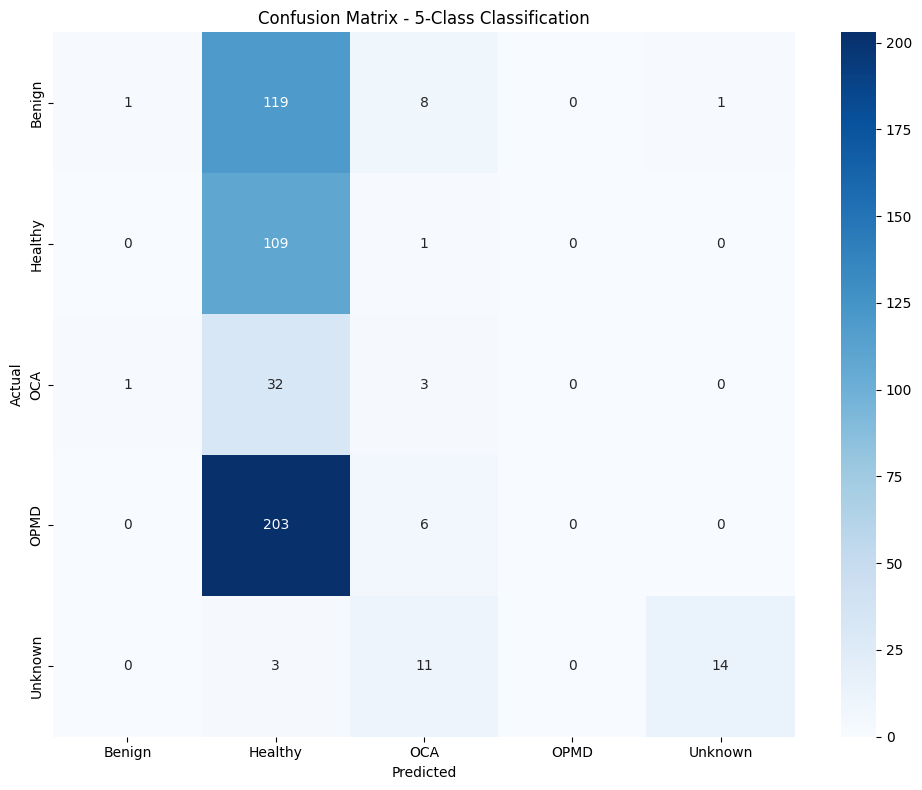


HEAD B: BINARY RISK (High-risk vs Low-risk)
              precision    recall  f1-score   support

    Low-risk       0.49      1.00      0.66       239
   High-risk       0.00      0.00      0.00       245

    accuracy                           0.49       484
   macro avg       0.25      0.50      0.33       484
weighted avg       0.24      0.49      0.33       484


Screening Metrics:
  Sensitivity (High-risk recall): 0.0000
  Specificity (Low-risk recall): 1.0000
  ROC-AUC: 0.5471
  TARGET NOT MET: Sensitivity < 0.90 (need threshold adjustment)

HEAD C: ORAL vs NON-ORAL (Unknown detection)
              precision    recall  f1-score   support

    Non-oral       1.00      0.50      0.67        28
        Oral       0.97      1.00      0.99       484

    accuracy                           0.97       512
   macro avg       0.99      0.75      0.83       512
weighted avg       0.97      0.97      0.97       512


Evaluation results saved to results/multihead_efficientnet/multihead_2

In [48]:
# Cell 10: Comprehensive Evaluation

# Load best model
print("Loading best model for evaluation...")
best_model = keras.models.load_model(output_path / 'models' / 'best_model.keras')

# Collect predictions on test set
print("\nEvaluating on test set...")
all_y_class = []
all_y_risk = []
all_y_oral = []
all_pred_class = []
all_pred_risk = []
all_pred_oral = []

test_steps = len(test_paths_5class) // CONFIG['batch_size']

for batch in tqdm(test_dataset.take(test_steps), desc="Testing"):
    images, (y_class, y_risk, y_oral, mask) = batch
    pred_class, pred_risk, pred_oral = best_model(images, training=False)
    
    all_y_class.extend(y_class.numpy())
    all_y_risk.extend(y_risk.numpy())
    all_y_oral.extend(y_oral.numpy())
    all_pred_class.extend(pred_class.numpy())
    all_pred_risk.extend(pred_risk.numpy().flatten())
    all_pred_oral.extend(pred_oral.numpy().flatten())

# Convert to arrays
y_true_class = np.array(all_y_class)
y_true_risk = np.array(all_y_risk)
y_true_oral = np.array(all_y_oral)
y_pred_class_probs = np.array(all_pred_class)
y_pred_class = np.argmax(y_pred_class_probs, axis=1)
y_pred_risk = np.array(all_pred_risk)
y_pred_oral = np.array(all_pred_oral)

# =============================================
# Head A: 5-class classification report
# =============================================
print("\n" + "=" * 60)
print("HEAD A: 5-CLASS CLASSIFICATION")
print("=" * 60)
print(classification_report(y_true_class, y_pred_class, target_names=CONFIG['class_names']))

# F1 scores
f1_weighted = f1_score(y_true_class, y_pred_class, average='weighted')
f1_macro = f1_score(y_true_class, y_pred_class, average='macro')
print(f"F1 Score (weighted): {f1_weighted:.4f}")
print(f"F1 Score (macro): {f1_macro:.4f}")

# Confusion matrix
cm = confusion_matrix(y_true_class, y_pred_class)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CONFIG['class_names'],
            yticklabels=CONFIG['class_names'])
plt.title('Confusion Matrix - 5-Class Classification')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(output_path / 'plots' / 'confusion_matrix_class.png', dpi=300)
plt.show()

# =============================================
# Head B: Binary risk evaluation
# =============================================
print("\n" + "=" * 60)
print("HEAD B: BINARY RISK (High-risk vs Low-risk)")
print("=" * 60)

# Only evaluate on non-Unknown samples
risk_mask = y_true_class != 4  # Unknown = 4
y_true_risk_valid = y_true_risk[risk_mask]
y_pred_risk_valid = y_pred_risk[risk_mask]
y_pred_risk_binary = (y_pred_risk_valid > 0.5).astype(int)

print(classification_report(y_true_risk_valid, y_pred_risk_binary, target_names=['Low-risk', 'High-risk']))

# Sensitivity (recall for high-risk) - CRITICAL for screening
from sklearn.metrics import recall_score, precision_score
sensitivity = recall_score(y_true_risk_valid, y_pred_risk_binary)
specificity = recall_score(y_true_risk_valid, y_pred_risk_binary, pos_label=0)
roc_auc = roc_auc_score(y_true_risk_valid, y_pred_risk_valid)

print(f"\nScreening Metrics:")
print(f"  Sensitivity (High-risk recall): {sensitivity:.4f}")
print(f"  Specificity (Low-risk recall): {specificity:.4f}")
print(f"  ROC-AUC: {roc_auc:.4f}")

if sensitivity >= 0.90:
    print(f"  TARGET MET: Sensitivity >= 0.90")
else:
    print(f"  TARGET NOT MET: Sensitivity < 0.90 (need threshold adjustment)")

# =============================================
# Head C: Oral vs Non-oral evaluation
# =============================================
print("\n" + "=" * 60)
print("HEAD C: ORAL vs NON-ORAL (Unknown detection)")
print("=" * 60)

y_pred_oral_binary = (y_pred_oral > 0.5).astype(int)
print(classification_report(y_true_oral, y_pred_oral_binary, target_names=['Non-oral', 'Oral']))

# Save evaluation results
evaluation_results = {
    'head_a': {
        'f1_weighted': float(f1_weighted),
        'f1_macro': float(f1_macro),
        'confusion_matrix': cm.tolist(),
    },
    'head_b': {
        'sensitivity': float(sensitivity),
        'specificity': float(specificity),
        'roc_auc': float(roc_auc),
    },
    'head_c': {
        'accuracy': float(np.mean(y_true_oral == y_pred_oral_binary)),
    }
}

with open(output_path / 'evaluation_results.json', 'w') as f:
    json.dump(evaluation_results, f, indent=2)

print(f"\nEvaluation results saved to {output_path / 'evaluation_results.json'}")

In [ ]:
# Cell 11: Temperature Scaling for Calibration

class TemperatureScaling:
    """
    Temperature scaling for probability calibration
    Improves reliability of confidence scores for screening
    """
    
    def __init__(self):
        self.temperature = 1.0
    
    def fit(self, logits: np.ndarray, labels: np.ndarray) -> float:
        """
        Find optimal temperature using validation set
        """
        from scipy.optimize import minimize_scalar
        from scipy.special import softmax
        
        def nll_loss(T):
            """Negative log-likelihood with temperature"""
            scaled_probs = softmax(logits / T, axis=1)
            # Clip to avoid log(0)
            scaled_probs = np.clip(scaled_probs, 1e-10, 1.0)
            nll = -np.mean(np.log(scaled_probs[np.arange(len(labels)), labels]))
            return nll
        
        # Optimize temperature
        result = minimize_scalar(nll_loss, bounds=(0.1, 10.0), method='bounded')
        self.temperature = result.x
        
        return self.temperature
    
    def calibrate(self, probs: np.ndarray) -> np.ndarray:
        """
        Apply temperature scaling to probabilities
        """
        from scipy.special import softmax
        
        # Convert probs to logits
        logits = np.log(np.clip(probs, 1e-10, 1.0))
        # Apply temperature
        return softmax(logits / self.temperature, axis=1)


# Calibrate using validation set
print("Calibrating probability scores...")

# Get validation predictions
val_y_class = []
val_pred_logits = []

for batch in val_dataset.take(validation_steps):
    images, (y_class, _, _, _) = batch
    pred_class, _, _ = best_model(images, training=False)
    val_y_class.extend(y_class.numpy())
    # Convert probs to logits for calibration
    logits = np.log(np.clip(pred_class.numpy(), 1e-10, 1.0))
    val_pred_logits.extend(logits)

val_y_class = np.array(val_y_class)
val_pred_logits = np.array(val_pred_logits)

# Fit temperature
calibrator = TemperatureScaling()
optimal_temp = calibrator.fit(val_pred_logits, val_y_class)
print(f"Optimal temperature: {optimal_temp:.4f}")

# Apply calibration to test predictions
calibrated_probs = calibrator.calibrate(y_pred_class_probs)

# Save calibration info
calibration_info = {
    'temperature': float(optimal_temp),
    'description': 'Temperature scaling for probability calibration'
}

with open(output_path / 'calibration.json', 'w') as f:
    json.dump(calibration_info, f, indent=2)

print(f"Calibration saved to {output_path / 'calibration.json'}")

In [ ]:
# Cell 12: TFLite Export with Quantization

def export_to_tflite(
    model: keras.Model,
    output_dir: Path,
    quantization: str = 'dynamic',
    representative_data: Optional[tf.data.Dataset] = None,
) -> str:
    """
    Export model to TFLite with various quantization options
    
    Args:
        model: Keras model to export
        output_dir: Directory to save TFLite model
        quantization: 'none', 'dynamic', or 'int8'
        representative_data: Dataset for INT8 calibration
    
    Returns:
        Path to saved TFLite model
    """
    print(f"\nExporting to TFLite with {quantization} quantization...")
    
    # Create converter
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    
    if quantization == 'dynamic':
        # Dynamic range quantization (recommended for most cases)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        suffix = 'dynamic'
        
    elif quantization == 'int8':
        # Full INT8 quantization (smallest model, requires calibration)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        
        if representative_data is not None:
            def representative_dataset_gen():
                for batch in representative_data.take(100):
                    images, _ = batch
                    for img in images:
                        yield [tf.expand_dims(img, 0)]
            
            converter.representative_dataset = representative_dataset_gen
        
        converter.target_spec.supported_ops = [
            tf.lite.OpsSet.TFLITE_BUILTINS_INT8,
            tf.lite.OpsSet.TFLITE_BUILTINS  # Fallback for unsupported ops
        ]
        suffix = 'int8'
        
    else:  # 'none' - float32
        suffix = 'float32'
    
    # Convert
    try:
        tflite_model = converter.convert()
        
        # Save model
        output_path = output_dir / f'oral_multihead_{suffix}.tflite'
        with open(output_path, 'wb') as f:
            f.write(tflite_model)
        
        # Calculate size
        size_mb = len(tflite_model) / (1024 * 1024)
        print(f"Saved: {output_path}")
        print(f"Size: {size_mb:.2f} MB")
        
        return str(output_path)
        
    except Exception as e:
        print(f"Conversion failed: {e}")
        return None


def verify_tflite_model(tflite_path: str, test_dataset: tf.data.Dataset) -> Dict:
    """Verify TFLite model outputs match Keras model"""
    print(f"\nVerifying TFLite model: {tflite_path}")
    
    # Load TFLite model
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    
    print(f"Input shape: {input_details[0]['shape']}")
    print(f"Input type: {input_details[0]['dtype']}")
    print(f"Number of outputs: {len(output_details)}")
    
    # Test inference
    for batch in test_dataset.take(1):
        images, _ = batch
        test_image = images[0:1].numpy()
        
        # Run inference
        interpreter.set_tensor(input_details[0]['index'], test_image)
        interpreter.invoke()
        
        # Get outputs
        outputs = [interpreter.get_tensor(d['index']) for d in output_details]
        
        print(f"\nTest inference:")
        for i, (out, detail) in enumerate(zip(outputs, output_details)):
            print(f"  Output {i} ({detail['name']}): shape={out.shape}")
    
    return {
        'input_shape': input_details[0]['shape'].tolist(),
        'input_type': str(input_details[0]['dtype']),
        'num_outputs': len(output_details),
    }


# Export with different quantization options
tflite_dir = output_path / 'tflite'

# 1. Dynamic range quantization (recommended)
tflite_dynamic = export_to_tflite(best_model, tflite_dir, 'dynamic')

# 2. Float32 (no quantization, for comparison)
tflite_float32 = export_to_tflite(best_model, tflite_dir, 'none')

# 3. INT8 with calibration (use 5-class dataset for representative samples)
tflite_int8 = export_to_tflite(best_model, tflite_dir, 'int8', train_dataset_5class)

# Verify the dynamic quantized model
if tflite_dynamic:
    verify_info = verify_tflite_model(tflite_dynamic, test_dataset)

In [ ]:
# Cell 13: Inference Test on Sample Images

def run_tflite_inference(tflite_path: str, image_path: str, class_names: List[str]) -> Dict:
    """
    Run inference on a single image using TFLite model
    
    Returns dict with predictions from all three heads
    """
    # Load model
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    
    # Load and preprocess image
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    img = img.astype(np.float32) / 255.0
    input_data = np.expand_dims(img, axis=0)
    
    # Run inference
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    
    # Get outputs (order may vary, find by name)
    outputs = {}
    for detail in output_details:
        name = detail['name']
        output = interpreter.get_tensor(detail['index'])[0]
        outputs[name] = output
    
    # Parse outputs
    # Find class output (shape should be num_classes)
    class_probs = None
    risk_score = None
    oral_score = None
    
    for name, output in outputs.items():
        if 'class' in name.lower() or len(output) == len(class_names):
            class_probs = output
        elif 'risk' in name.lower():
            risk_score = float(output[0]) if len(output.shape) > 0 else float(output)
        elif 'oral' in name.lower():
            oral_score = float(output[0]) if len(output.shape) > 0 else float(output)
    
    # Handle case where outputs aren't named as expected
    if class_probs is None:
        # Assume first output with 5 elements is class output
        for output in outputs.values():
            if len(output) == len(class_names):
                class_probs = output
                break
    
    pred_class_idx = int(np.argmax(class_probs)) if class_probs is not None else -1
    pred_class = class_names[pred_class_idx] if pred_class_idx >= 0 else 'Unknown'
    confidence = float(np.max(class_probs)) if class_probs is not None else 0.0
    
    return {
        'predicted_class': pred_class,
        'confidence': confidence,
        'class_probabilities': {name: float(prob) for name, prob in zip(class_names, class_probs)} if class_probs is not None else {},
        'risk_score': risk_score,
        'is_high_risk': risk_score > 0.5 if risk_score is not None else None,
        'oral_score': oral_score,
        'is_oral': oral_score > 0.5 if oral_score is not None else None,
    }


# Test on sample images from test_data
test_data_dir = Path('../../test_data')
if test_data_dir.exists():
    print("Testing TFLite model on sample images...")
    print("=" * 60)
    
    test_files = list(test_data_dir.glob('*.jpg')) + list(test_data_dir.glob('*.jpeg')) + list(test_data_dir.glob('*.png'))
    
    results = []
    for img_path in sorted(test_files)[:10]:
        filename = img_path.name
        expected = filename.split('_')[0] if '_' in filename else 'unknown'
        
        try:
            result = run_tflite_inference(tflite_dynamic, str(img_path), CONFIG['class_names'])
            result['filename'] = filename
            result['expected'] = expected
            result['correct'] = result['predicted_class'].lower() == expected.lower()
            results.append(result)
            
            status = 'O' if result['correct'] else 'X'
            risk_str = 'HIGH' if result['is_high_risk'] else 'LOW' if result['is_high_risk'] is not None else 'N/A'
            print(f"[{status}] {filename:30} | Pred: {result['predicted_class']:8} ({result['confidence']:.2f}) | Risk: {risk_str}")
            
        except Exception as e:
            print(f"[E] {filename}: {e}")
    
    # Summary
    correct = sum(1 for r in results if r['correct'])
    total = len(results)
    print(f"\nAccuracy: {correct}/{total} ({correct/total*100:.1f}%)")
    
    # Save results
    results_df = pd.DataFrame(results)
    results_df.to_csv(output_path / 'tflite_test_results.csv', index=False)
else:
    print(f"Test data directory not found: {test_data_dir}")
    print("Skipping inference test.")

In [ ]:
# Cell 14: Results Summary and Report Generation

print("\n" + "=" * 60)
print("TRAINING RESULTS SUMMARY")
print("=" * 60)

# Load evaluation results
with open(output_path / 'evaluation_results.json', 'r') as f:
    eval_results = json.load(f)

# Print summary
print(f"\nExperiment: {CONFIG['experiment_name']}")
print(f"Backbone: {CONFIG['backbone']}")
print(f"Training epochs: {len(history['train_loss'])}")

print(f"\nHEAD A (5-class classification):")
print(f"  F1 Score (weighted): {eval_results['head_a']['f1_weighted']:.4f}")
print(f"  F1 Score (macro): {eval_results['head_a']['f1_macro']:.4f}")

print(f"\nHEAD B (Risk detection):")
print(f"  Sensitivity: {eval_results['head_b']['sensitivity']:.4f}")
print(f"  Specificity: {eval_results['head_b']['specificity']:.4f}")
print(f"  ROC-AUC: {eval_results['head_b']['roc_auc']:.4f}")

print(f"\nHEAD C (Oral detection):")
print(f"  Accuracy: {eval_results['head_c']['accuracy']:.4f}")

# List exported models
print(f"\nExported TFLite models:")
for tflite_file in (output_path / 'tflite').glob('*.tflite'):
    size_mb = tflite_file.stat().st_size / (1024 * 1024)
    print(f"  {tflite_file.name}: {size_mb:.2f} MB")

# Recommendations
print(f"\n" + "=" * 60)
print("RECOMMENDATIONS")
print("=" * 60)

f1_weighted = eval_results['head_a']['f1_weighted']
sensitivity = eval_results['head_b']['sensitivity']

if f1_weighted >= 0.80:
    print("[PASS] F1 Score >= 0.80 - Model meets accuracy target")
else:
    print(f"[NEEDS WORK] F1 Score = {f1_weighted:.3f} < 0.80")
    print("  - Consider more training data")
    print("  - Try stronger augmentation")
    print("  - Experiment with EfficientNetB3 backbone")

if sensitivity >= 0.90:
    print("[PASS] Sensitivity >= 0.90 - Safe for screening use")
else:
    print(f"[CRITICAL] Sensitivity = {sensitivity:.3f} < 0.90")
    print("  - Adjust risk threshold (lower from 0.5)")
    print("  - Increase beta loss weight")
    print("  - Add more high-risk training samples")

# Plot training curves
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train')
axes[0, 0].plot(history['val_loss'], label='Validation')
axes[0, 0].set_title('Total Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Class Accuracy
axes[0, 1].plot(history['train_class_acc'], label='Train')
axes[0, 1].plot(history['val_class_acc'], label='Validation')
axes[0, 1].set_title('5-Class Accuracy')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Risk Accuracy
axes[1, 0].plot(history['train_risk_acc'], label='Train')
axes[1, 0].plot(history['val_risk_acc'], label='Validation')
axes[1, 0].set_title('Risk Detection Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Learning Rate
axes[1, 1].plot(history['learning_rate'])
axes[1, 1].set_title('Learning Rate')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('LR')
axes[1, 1].set_yscale('log')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(output_path / 'plots' / 'training_curves.png', dpi=300)
plt.show()

print(f"\nAll results saved to: {output_path}")
print(f"\nNext steps:")
print(f"  1. Copy TFLite model to Flutter assets:")
print(f"     cp {output_path / 'tflite' / 'oral_multihead_dynamic.tflite'} ../../assets/")
print(f"  2. Update Flutter model inference service with 3-output handling")
print(f"  3. Test on real device")